# AI-Powered Real-Time Fraud Risk Assessment System
## Raw data exploratory analysis

This notebook profiles the source exports in `data/raw`: schemas, missingness, duplicates, numeric distributions, transaction activity, and product/traffic data. The transaction files contain order and location identifiers; this notebook intentionally reports aggregates and never displays raw transaction rows.

**Important:** descriptive anomalies are investigation leads, not proof of fraud. A supervised fraud model requires a verified fraud/chargeback outcome label.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 40)

def find_project_root(start: Path = Path.cwd()) -> Path:
    """Find the repository root without relying on the notebook working directory."""
    for candidate in (start, *start.parents):
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a data/raw directory above the notebook.")

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
raw_files = sorted(p for p in RAW_DIR.iterdir() if p.is_file() and p.suffix.lower() in {".csv", ".xlsx", ".xls"})
if not raw_files:
    raise FileNotFoundError(f"No CSV or Excel files found in {RAW_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data files found: {len(raw_files)}")
for path in raw_files:
    print(f"- {path.name} ({path.stat().st_size / (1024 ** 2):.2f} MiB)")

Project root: E:\AI-POWERED REAL-TIME FRAUD RISK ASSESSMENT
Raw data files found: 7
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Detail Page Sales and Traffic Report_Last 12 months_2026-09-25.csv (0.04 MiB)
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Detail Page Sales and Traffic Report_Last 30 days_2026-09-25.csv (0.02 MiB)
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Fee Preview_NA_2026-09-25.csv (0.02 MiB)
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Keepa_NA_2026-09-25.csv (0.17 MiB)
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Transaction Report_Last 12 months_2026-09-25.csv (80.60 MiB)
- Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Transaction Report_Last 14 days_2026-09-25.csv (6.62 MiB)
- Mammoth_E-commerce_Ltd_Products_(2026_09_25_14_53_42_760)_sellerboard.com.xlsx (0.12 MiB)


## Load source files

Amazon transaction exports contain nine metadata lines before the table header. Other CSVs start with their header. Excel sheets are loaded separately. No `head()` output is used, to avoid exposing customer or order identifiers.

In [2]:
datasets = {}
for path in raw_files:
    if path.suffix.lower() == ".csv":
        skiprows = 9 if "transaction report" in path.name.lower() else 0
        frame = pd.read_csv(
            path,
            encoding="utf-8-sig",
            encoding_errors="replace",
            skiprows=skiprows,
            low_memory=False,
        )
        datasets[path.stem] = frame
    else:
        sheets = pd.read_excel(path, sheet_name=None)
        for sheet_name, frame in sheets.items():
            datasets[f"{path.stem} — {sheet_name}"] = frame

file_overview = pd.DataFrame(
    [{"dataset": name, "rows": len(frame), "columns": len(frame.columns)} for name, frame in datasets.items()]
).sort_values("dataset", ignore_index=True)
display(file_overview)

,dataset,rows,columns
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,146,22
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,70,22
2,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,57,31
3,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,78,154
4,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,226932,29
5,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,24217,29
6,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,1319,15


## Structure, missingness, and label availability

The summary below reports column names, inferred types, missing counts, and distinct-value counts only. High-cardinality columns can include identifiers, but their values are never displayed.

In [3]:
schema_rows = []
for dataset_name, frame in datasets.items():
    for column in frame.columns:
        series = frame[column]
        schema_rows.append({
            "dataset": dataset_name,
            "column": str(column),
            "dtype": str(series.dtype),
            "missing_count": int(series.isna().sum()),
            "missing_pct": float(series.isna().mean() * 100) if len(series) else 0.0,
            "distinct_non_null": int(series.nunique(dropna=True)),
        })
schema = pd.DataFrame(schema_rows)
display(schema.sort_values(["dataset", "missing_pct"], ascending=[True, False], ignore_index=True))

label_terms = ("fraud", "chargeback", "dispute")
label_columns = [
    (dataset_name, str(column))
    for dataset_name, frame in datasets.items()
    for column in frame.columns
    if any(term in str(column).lower() for term in label_terms)
]
print("Potential fraud/outcome label columns:", label_columns if label_columns else "None found")
if not label_columns:
    print("No explicit fraud, chargeback, dispute, or target label was found; supervised fraud classification is not supported by these exports alone.")

,dataset,column,dtype,missing_count,missing_pct,distinct_non_null
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,(Parent) ASIN,object,0,0.0,48
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,(Child) ASIN,object,0,0.0,79
2,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Title,object,0,0.0,77
3,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,SKU,object,0,0.0,79
4,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Sessions – Total,object,0,0.0,140
...,...,...,...,...,...,...
297,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,ASIN,object,0,0.0,1293
298,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,Title,object,0,0.0,1146
299,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,VAT,int64,0,0.0,1
300,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,VAT_CATEGORY,object,0,0.0,1


Potential fraud/outcome label columns: None found
No explicit fraud, chargeback, dispute, or target label was found; supervised fraud classification is not supported by these exports alone.


In [4]:
duplicate_rows = pd.DataFrame([
    {"dataset": name, "duplicate_rows": int(frame.duplicated().sum()), "duplicate_pct": float(frame.duplicated().mean() * 100) if len(frame) else 0.0}
    for name, frame in datasets.items()
])
display(duplicate_rows.sort_values("duplicate_rows", ascending=False, ignore_index=True))

numeric_profiles = []
for name, frame in datasets.items():
    numeric = frame.select_dtypes(include="number")
    if not numeric.empty:
        summary = numeric.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
        summary.insert(0, "dataset", name)
        summary.insert(1, "column", summary.index)
        numeric_profiles.append(summary.reset_index(drop=True))
if numeric_profiles:
    numeric_profile = pd.concat(numeric_profiles, ignore_index=True)
    display(numeric_profile)
else:
    print("No columns were inferred as numeric. Transaction financial fields are parsed in the next section.")

,dataset,duplicate_rows,duplicate_pct
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,10002,4.407488
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,3768,15.559318
2,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,0,0.000000
3,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,0,0.000000
4,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,0,0.000000
5,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,0,0.000000
6,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,0,0.000000


,dataset,column,count,mean,std,min,1%,25%,50%,75%,99%,max
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Units ordered – B2B,146.0,22.061644,44.517214,0.0,0.0,1.0,5.0,24.50,237.30,305.0
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Total order items – B2B,146.0,18.006849,36.638118,0.0,0.0,1.0,4.0,18.50,187.15,260.0
2,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Sessions – Total – B2B,70.0,20.900000,40.623100,0.0,0.0,2.0,5.0,21.75,213.92,236.0
3,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Page views – Total – B2B,70.0,27.300000,54.729996,0.0,0.0,2.0,5.5,25.00,291.16,316.0
4,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,Units ordered – B2B,70.0,6.657143,14.751945,0.0,0.0,0.0,1.0,5.75,70.92,93.0
...,...,...,...,...,...,...,...,...,...,...,...,...
134,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,RestofworldShippingCost,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
135,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,ShippingProfile,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
136,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,Value_of_unsellable_returns,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
137,Mammoth_E-commerce_Ltd_Products_(2026_09_25_14...,VAT,1319.0,20.000000,0.000000,20.0,20.0,20.0,20.0,20.00,20.00,20.0


## Transaction activity and amount distributions

Transaction amount fields sometimes arrive as text. Convert relevant financial and quantity columns for analysis, parse the transaction timestamp, and aggregate by date/type/status. The detailed table may contain order/location identifiers, so plots and summaries below deliberately exclude those dimensions.

In [5]:
transaction_names = [name for name in datasets if "transaction report" in name.lower()]
if not transaction_names:
    print("No transaction report export detected.")
else:
    transaction_frames = {}
    amount_columns = [
        "product sales", "product sales tax", "postage credits", "shipping credits tax",
        "gift wrap credits", "giftwrap credits tax", "promotional rebates",
        "promotional rebates tax", "marketplace withheld tax", "selling fees",
        "fba fees", "other transaction fees", "other", "total", "quantity",
    ]
    for name in transaction_names:
        frame = datasets[name].copy()
        for column in amount_columns:
            if column in frame.columns:
                cleaned = frame[column].astype("string").str.strip()
                cleaned = cleaned.str.replace(",", "", regex=False)
                cleaned = cleaned.str.replace(r"[^0-9.eE+()-]", "", regex=True)
                cleaned = cleaned.str.replace(r"^\((.*)\)$", r"-\1", regex=True)
                frame[column] = pd.to_numeric(cleaned, errors="coerce")
        if "date/time" in frame.columns:
            frame["date/time"] = pd.to_datetime(frame["date/time"], errors="coerce", dayfirst=True)
        transaction_frames[name] = frame

    transaction_counts = pd.DataFrame([
        {
            "dataset": name,
            "rows": len(frame),
            "unparsed_dates": int(frame["date/time"].isna().sum()) if "date/time" in frame else None,
            "date_min": frame["date/time"].min() if "date/time" in frame else None,
            "date_max": frame["date/time"].max() if "date/time" in frame else None,
            "negative_total_rows": int(frame["total"].lt(0).sum()) if "total" in frame else None,
            "zero_total_rows": int(frame["total"].eq(0).sum()) if "total" in frame else None,
        }
        for name, frame in transaction_frames.items()
    ])
    display(transaction_counts)

    primary_name = next((name for name in transaction_frames if "12 months" in name.lower()), transaction_names[0])
    tx = transaction_frames[primary_name]
    print(f"Primary transaction dataset for charts: {primary_name}")
    if "type" in tx.columns and "total" in tx.columns:
        duplicate_rows = tx.duplicated()
        print(f"Exact duplicate rows: {int(duplicate_rows.sum()):,} ({duplicate_rows.mean():.1%}); review before deduplicating because repeated adjustment entries may be valid.")
        duplicate_types = tx.loc[duplicate_rows, "type"].value_counts(dropna=False).head(10)
        display(duplicate_types.rename_axis("type").to_frame("duplicate_rows"))
        by_type = tx.groupby("type", dropna=False).agg(
            transactions=("total", "size"),
            total_amount=("total", "sum"),
            median_amount=("total", "median"),
            negative_amount_rows=("total", lambda values: int(values.lt(0).sum())),
        ).sort_values("transactions", ascending=False)
        display(by_type)
    if "Transaction status" in tx.columns:
        display(tx["Transaction status"].fillna("(missing)").value_counts(dropna=False).rename_axis("status").to_frame("count"))

C:\Users\turab\AppData\Local\Temp\ipykernel_36432\935416002.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  frame["date/time"] = pd.to_datetime(frame["date/time"], errors="coerce", dayfirst=True)


C:\Users\turab\AppData\Local\Temp\ipykernel_36432\935416002.py:22: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  frame["date/time"] = pd.to_datetime(frame["date/time"], errors="coerce", dayfirst=True)


,dataset,rows,unparsed_dates,date_min,date_max,negative_total_rows,zero_total_rows
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,226932,0,2025-09-23 23:00:06+00:00,2026-09-23 22:59:59+00:00,7810,69
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,24217,0,2026-09-09 23:00:25+00:00,2026-09-24 22:59:56+00:00,575,5


Primary transaction dataset for charts: Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Transaction Report_Last 12 months_2026-09-25


Exact duplicate rows: 10,002 (4.4%); review before deduplicating because repeated adjustment entries may be valid.


,duplicate_rows
type,
Adjustment,9965
Order,35
FBA Inventory Fee,1
Fee Adjustment,1


,transactions,total_amount,median_amount,negative_amount_rows
type,,,,
Order,198384,2232297.1,10.51,1792.0
Adjustment,20738,27984.55,1.14,226.0
Refund,4268,-60984.56,-14.71,3919.0
Fee Adjustment,1597,410.55,0.26,0.0
FBA Inventory Fee,1051,-44409.78,-4.34,1050.0
Amazon Fees,355,-20321.4,-42.0,355.0
Fulfilment by Amazon (FBA) transaction fees,239,-20917.06,-5.95,239.0
Transfer,208,-2048243.86,-7502.05,208.0
Order_Retrocharge,66,111.76,1.335,0.0


,count
status,
Released,220910
Deferred,6022


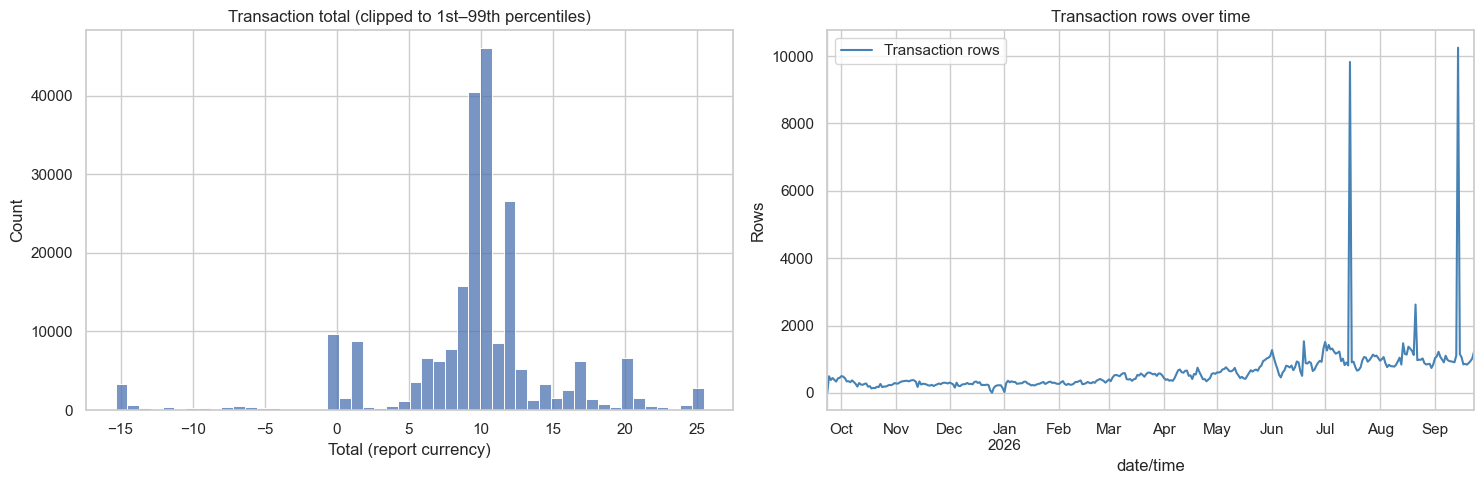

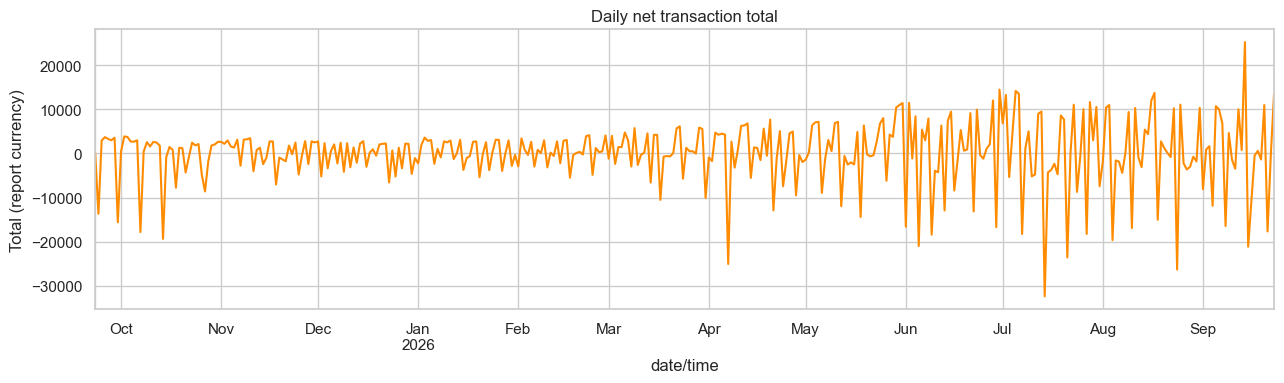

In [6]:
if transaction_names:
    tx = transaction_frames[primary_name]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    if "total" in tx.columns:
        values = tx["total"].dropna()
        if not values.empty:
            lower, upper = values.quantile([0.01, 0.99])
            sns.histplot(values.clip(lower, upper), bins=50, ax=axes[0])
            axes[0].set_title("Transaction total (clipped to 1st–99th percentiles)")
            axes[0].set_xlabel("Total (report currency)")
    if "date/time" in tx.columns and "total" in tx.columns:
        daily = tx.dropna(subset=["date/time"]).set_index("date/time").resample("D").agg(
            transactions=("total", "size"), total_amount=("total", "sum")
        )
        daily["transactions"].plot(ax=axes[1], color="steelblue", label="Transaction rows")
        axes[1].set_title("Transaction rows over time")
        axes[1].set_ylabel("Rows")
        axes[1].legend()
    plt.tight_layout()
    plt.show()

    if "date/time" in tx.columns and "total" in tx.columns:
        daily_amount = tx.dropna(subset=["date/time"]).set_index("date/time")["total"].resample("D").sum()
        ax = daily_amount.plot(figsize=(13, 4), color="darkorange")
        ax.set_title("Daily net transaction total")
        ax.set_ylabel("Total (report currency)")
        plt.tight_layout()
        plt.show()

## Cross-export checks and product/traffic summaries

Check overlap between the recent and long transaction windows using counts and row hashes only; never emit order-level keys. For product, fee, Keepa, and traffic exports, summarize available numeric fields and product counts. Treat missingness or extreme values as data-quality/risk-review signals, not fraud labels.

In [7]:
long_name = next((name for name in transaction_names if "12 months" in name.lower()), None)
recent_name = next((name for name in transaction_names if "14 days" in name.lower()), None)
if long_name and recent_name:
    long_frame = transaction_frames[long_name]
    recent_frame = transaction_frames[recent_name]
    comparable_columns = [column for column in long_frame.columns if column in recent_frame.columns]
    long_hashes = pd.util.hash_pandas_object(long_frame[comparable_columns], index=False)
    recent_hashes = pd.util.hash_pandas_object(recent_frame[comparable_columns], index=False)
    recent_in_long = int(recent_hashes.isin(set(long_hashes)).sum())
    print(f"Recent-window rows present in 12-month export by full-row match: {recent_in_long:,} / {len(recent_frame):,}")
    print("The reports overlap in time; do not add their totals together.")

for name, frame in datasets.items():
    if "transaction report" in name.lower():
        continue
    print(f"\n{name}: {len(frame):,} rows × {len(frame.columns):,} columns")
    id_candidates = [column for column in frame.columns if any(token in str(column).lower() for token in ("asin", "sku", "fnsku"))]
    for column in id_candidates:
        print(f"  {column}: {frame[column].nunique(dropna=True):,} distinct non-null identifiers")
    numeric = frame.select_dtypes(include="number")
    if not numeric.empty:
        display(numeric.describe(percentiles=[0.5, 0.95, 0.99]).T)

Recent-window rows present in 12-month export by full-row match: 23,019 / 24,217
The reports overlap in time; do not add their totals together.

Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Detail Page Sales and Traffic Report_Last 12 months_2026-09-25: 146 rows × 22 columns
  (Parent) ASIN: 48 distinct non-null identifiers
  (Child) ASIN: 79 distinct non-null identifiers
  SKU: 79 distinct non-null identifiers


,count,mean,std,min,50%,95%,99%,max
Units ordered – B2B,146.0,22.061644,44.517214,0.0,5.0,92.0,237.30,305.0
Total order items – B2B,146.0,18.006849,36.638118,0.0,4.0,70.5,187.15,260.0



Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Detail Page Sales and Traffic Report_Last 30 days_2026-09-25: 70 rows × 22 columns
  (Parent) ASIN: 24 distinct non-null identifiers
  (Child) ASIN: 63 distinct non-null identifiers
  SKU: 63 distinct non-null identifiers


,count,mean,std,min,50%,95%,99%,max
Sessions – Total – B2B,70.0,20.900000,40.623100,0.0,5.0,74.10,213.92,236.0
Page views – Total – B2B,70.0,27.300000,54.729996,0.0,5.5,93.10,291.16,316.0
Units ordered – B2B,70.0,6.657143,14.751945,0.0,1.0,30.60,70.92,93.0
Total order items – B2B,70.0,5.485714,11.229804,0.0,1.0,24.85,54.58,67.0



Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Fee Preview_NA_2026-09-25: 57 rows × 31 columns
  sku: 57 distinct non-null identifiers
  fnsku: 57 distinct non-null identifiers
  asin: 57 distinct non-null identifiers


,count,mean,std,min,50%,95%,99%,max
your-price,57.0,27.824211,11.729340,9.99,24.99,49.990,49.990,49.99
sales-price,57.0,27.824211,11.729340,9.99,24.99,49.990,49.990,49.99
longest-side,57.0,26.919298,5.714885,11.60,30.00,31.240,33.712,35.00
median-side,57.0,19.274561,6.328736,6.00,23.00,25.000,25.000,25.00
shortest-side,57.0,8.421404,4.057337,1.40,8.29,16.000,16.748,17.70
length-and-girth,57.0,82.311228,23.272085,29.70,92.00,112.000,112.000,112.00
item-package-weight,57.0,1581.580175,1247.093079,40.01,1250.01,4542.006,4569.990,4569.99
estimated-fee-total,57.0,6.920877,2.460313,2.64,7.15,10.958,11.154,11.21
estimated-referral-fee-per-unit,57.0,3.818421,2.135685,0.80,3.75,7.500,7.500,7.50
estimated-variable-closing-fee,57.0,0.000000,0.000000,0.00,0.00,0.000,0.000,0.00



Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing Table-Offer_Keepa_NA_2026-09-25: 78 rows × 154 columns
  ASIN: 78 distinct non-null identifiers
  Parent ASIN: 19 distinct non-null identifiers


,count,mean,std,min,50%,95%,99%,max
Sales Rank: Current,76.0,7873.000000,19431.830499,16.0,1838.5,21899.00,109000.00,110860.0
Sales Rank: 90 days avg.,76.0,9087.736842,17756.564542,65.0,2898.0,32319.00,82631.00,111011.0
Sales Rank: Drops last 90 days,78.0,43.358974,25.697528,0.0,43.5,82.35,93.46,95.0
Monthly Sales Trends: Bought in past month,36.0,616.666667,1081.401207,50.0,200.0,2500.00,4650.00,5000.0
Return Rate,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
Item: Weight (g),20.0,782.000000,441.762022,100.0,940.0,1457.00,1563.40,1590.0
Special Ingredients,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
One Time Coupon: Percentage,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
One Time Coupon: Subscribe & Save %,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Mammoth_E-commerce_Ltd_Products_(2026_09_25_14_53_42_760)_sellerboard.com — TDSheet: 1,319 rows × 15 columns
  ASIN: 1,293 distinct non-null identifiers
  SKU: 568 distinct non-null identifiers


,count,mean,std,min,50%,95%,99%,max
Cost,99.0,5.836364,3.297261,0.48,5.52,12.6,14.2346,14.95
DomesticShippingCost,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestofworldShippingCost,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ShippingProfile,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Value_of_unsellable_returns,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
VAT,1319.0,20.000000,0.000000,20.00,20.00,20.0,20.0000,20.00
BatchQuantity,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dataset,products,Sessions – Total total,Sessions – Total missing,Page views – Total total,Page views – Total missing,Units ordered total,Units ordered missing,Ordered Product Sales total,Ordered Product Sales missing,Total order items total,Total order items missing,weighted units per session
0,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,146,784130,0,1071502,0,204695,0,3473377.75,0,195688,0,0.261047
1,Felix Murphy_Mammoth E-commerce Ltd_UK_Pricing...,70,104797,0,142629,0,28931,0,504615.35,0,27627,0,0.276067


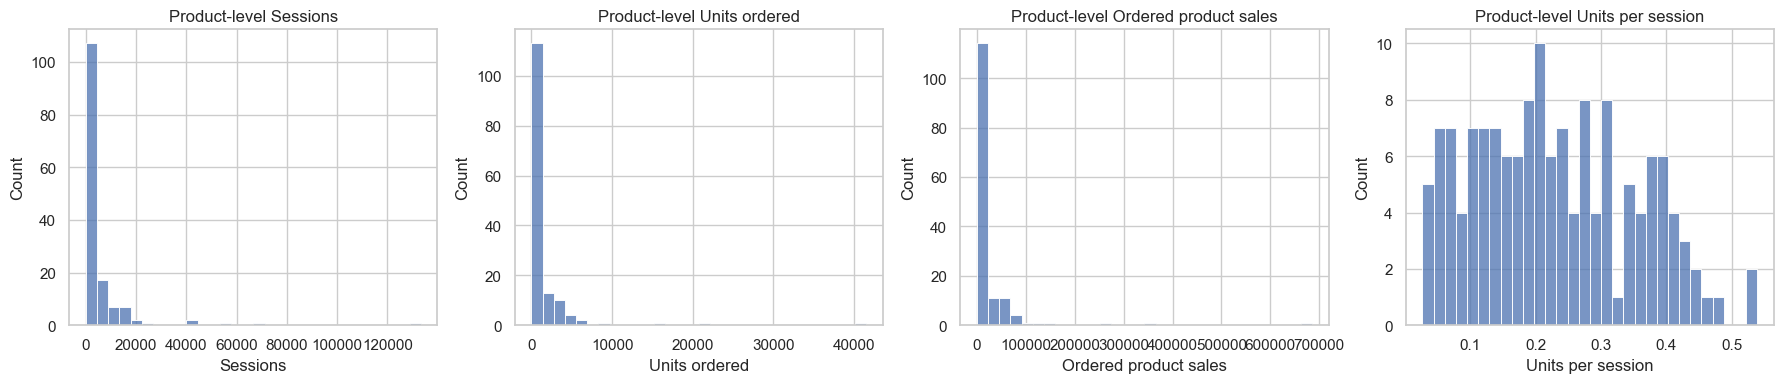

Product workbook sheet 'TDSheet': 1,319 rows, 15 columns
Product label coverage: 68/1,319 populated


,products
label,
(missing),1251
#FBA,68


In [8]:
traffic_names = [name for name in datasets if "detail page sales and traffic report" in name.lower()]
traffic_frames = {}
for name in traffic_names:
    frame = datasets[name].copy()
    for column in frame.columns:
        normalized = str(column).lower()
        if any(metric in normalized for metric in ("sessions", "page views", "units ordered", "ordered product sales", "total order items")) and "percentage" not in normalized:
            cleaned = frame[column].astype("string").str.strip()
            cleaned = cleaned.str.replace(",", "", regex=False)
            cleaned = cleaned.str.replace(r"[^0-9.eE+()-]", "", regex=True)
            cleaned = cleaned.str.replace(r"^\((.*)\)$", r"-\1", regex=True)
            frame[column] = pd.to_numeric(cleaned, errors="coerce")
    traffic_frames[name] = frame

traffic_summary = []
for name, frame in traffic_frames.items():
    row = {"dataset": name, "products": len(frame)}
    for column in frame.columns:
        normalized = str(column).lower()
        if any(metric in normalized for metric in ("sessions", "page views", "units ordered", "ordered product sales", "total order items")) and "percentage" not in normalized and "b2b" not in normalized:
            values = pd.to_numeric(frame[column], errors="coerce")
            row[f"{column} total"] = values.sum(min_count=1)
            row[f"{column} missing"] = int(values.isna().sum())
    sessions_column = next((c for c in frame.columns if "sessions" in str(c).lower() and "b2b" not in str(c).lower() and "percentage" not in str(c).lower()), None)
    units_column = next((c for c in frame.columns if "units ordered" in str(c).lower() and "b2b" not in str(c).lower()), None)
    if sessions_column and units_column:
        sessions = pd.to_numeric(frame[sessions_column], errors="coerce").sum()
        units = pd.to_numeric(frame[units_column], errors="coerce").sum()
        row["weighted units per session"] = units / sessions if sessions else float("nan")
    traffic_summary.append(row)
display(pd.DataFrame(traffic_summary))

if traffic_frames:
    long_traffic_name = next((n for n in traffic_frames if "12 months" in n.lower()), next(iter(traffic_frames)))
    traffic = traffic_frames[long_traffic_name]
    sessions_column = next((c for c in traffic.columns if "sessions" in str(c).lower() and "b2b" not in str(c).lower() and "percentage" not in str(c).lower()), None)
    units_column = next((c for c in traffic.columns if "units ordered" in str(c).lower() and "b2b" not in str(c).lower()), None)
    sales_column = next((c for c in traffic.columns if "ordered product sales" in str(c).lower() and "b2b" not in str(c).lower()), None)
    if sessions_column and units_column and sales_column:
        plot_data = traffic[[sessions_column, units_column, sales_column]].copy()
        plot_data.columns = ["Sessions", "Units ordered", "Ordered product sales"]
        plot_data["Units per session"] = plot_data["Units ordered"] / plot_data["Sessions"].replace(0, pd.NA)
        fig, axes = plt.subplots(1, 4, figsize=(18, 4))
        for axis, column in zip(axes, plot_data.columns):
            sns.histplot(plot_data[column].dropna(), bins=30, ax=axis)
            axis.set_title(f"Product-level {column}")
        plt.tight_layout()
        plt.show()

    product_book = next((p for p in raw_files if p.suffix.lower() in {".xlsx", ".xls"}), None)
    if product_book:
        for sheet_name, product_frame in pd.read_excel(product_book, sheet_name=None).items():
            print(f"Product workbook sheet {sheet_name!r}: {len(product_frame):,} rows, {len(product_frame.columns)} columns")
            if "Labels" in product_frame.columns:
                print("Product label coverage:", f"{product_frame['Labels'].notna().sum():,}/{len(product_frame):,} populated")
                display(product_frame["Labels"].fillna("(missing)").value_counts().rename_axis("label").to_frame("products"))


## EDA notes and next steps

Use the tables and charts above to document findings. In particular:

- Validate parsing, date coverage, duplicate records, missing values, and unexpected negative or zero amounts.
- Investigate unusual transaction types, value tails, and daily activity spikes against marketplace/accounting context.
- Confirm the currency and accounting semantics of each amount before interpreting net totals.
- The available transaction export is not known to contain a fraud outcome label. If none appears in the label check, obtain a trustworthy chargeback/dispute/fraud label joined under an approved process before training or evaluating a fraud classifier.
- Do not treat order identifiers, postal codes, or customer data as model features without an explicit privacy and governance review.
